In [63]:
import numpy as np
from matplotlib import pyplot
from open_atmos_jupyter_utils import show_plot, show_anim
from PyMPDATA import ScalarField, Solver, Stepper, VectorField, Options, boundary_conditions
from scipy.ndimage import zoom

## W jaki sposób kształt dna wpływa na propagację fali?

Celem projektu jest zbadanie wpływu ukształtowania dna na propagację fal w modelu płytkiej wody. Analizowane są dwa przypadki: zmiana amplitudy sinusoidalnego dna oraz fazy początkowej przy stałej amplitudzie. W obu przypadkach zachowano takie same pozostałe parametry symulacji: obliczenia przeprowadzono dla kroku przestrzennego $dx,dy=0.5$, czasu końcowego $T=7$, amplitudzie początkowego zaburzenia $A_0 = 0.025$ oraz przyspieszeniu grawitacyjnym $g=10$. Przeprowadzono również analizę zbieżności względem kroku przestrzennego i czasowego.


## Przykładowe profile dna

Do przeprowadzenia symulacji wykorzystano równania płytkiej wody oraz bibliotekę PyMPDATA. Na wykresie przedstawiono dwa przykładowe profile sinusoidalnego dna. Różnią się one amplitudą, jak i fazą początkową.

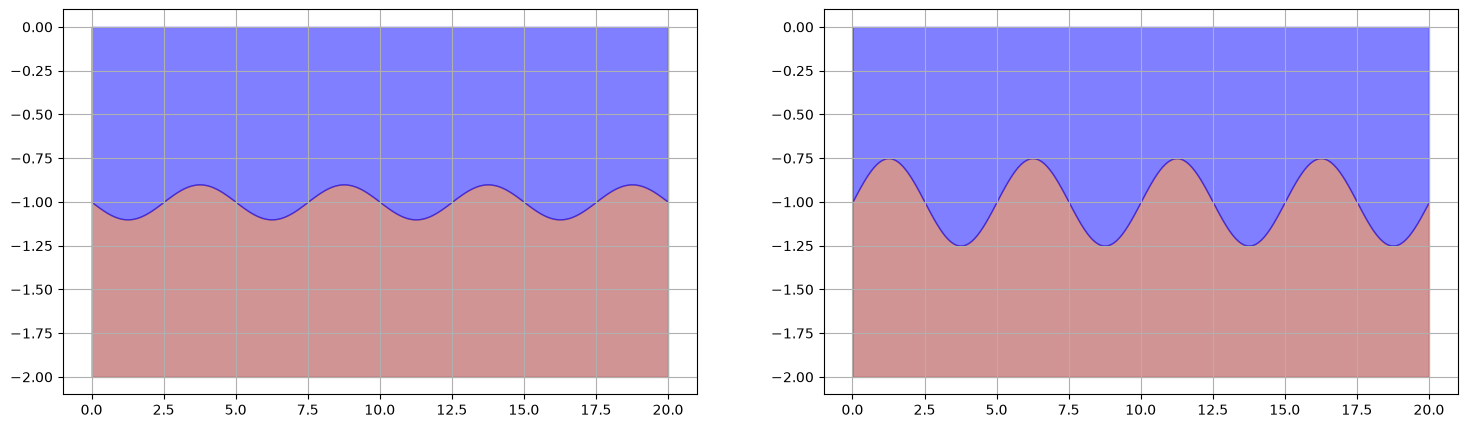

In [64]:
y = np.linspace(0,20,200)

b_sine_1 = 1 + 0.1 * np.sin(2 * np.pi * 4 * y / 20) 
h0_sine_1 = b_sine_1 

b_sine_2 = 1 + 0.25 * np.sin(2 * np.pi * 4 * y / 20 + np.pi) 
h0_sine_2 = b_sine_2 

fig, ax = pyplot.subplots(1, 2, figsize=(18, 5))
ax[0].fill_between(y, -2*np.ones_like(y), -b_sine_1, color='brown', alpha=.5)
ax[0].fill_between(y, -b_sine_1, h0_sine_1-b_sine_1, color='blue', alpha=.5)


ax[1].fill_between(y, -2*np.ones_like(y), -b_sine_2, color='brown', alpha=.5)
ax[1].fill_between(y, -b_sine_2, h0_sine_2-b_sine_2, color='blue', alpha=.5)

for a in ax:
    a.grid()

In [65]:
class ShallowWaterEquationsIntegratorWithBathymetry:
    def __init__(self, *, h_initial: np.ndarray, bathymetry: np.ndarray, options: Options = None):
        options = options or Options(nonoscillatory=True, infinite_gauge=True)
        self.bathymetry = bathymetry
        X, Y, grid = 0, 1, h_initial.shape
        stepper = Stepper(options=options, grid=grid)
        kwargs = {
            'boundary_conditions': [boundary_conditions.Constant(0)] * len(grid),
            'halo': options.n_halo,
        }
        advectees = {
            "h": ScalarField(h_initial, **kwargs),
            "uh": ScalarField(np.zeros(grid), **kwargs),
            "vh": ScalarField(np.zeros(grid), **kwargs),
        }
        self.advector = VectorField((
                np.zeros((grid[X] + 1, grid[Y])),
                np.zeros((grid[X], grid[Y] + 1))
            ), **kwargs
        )
        self.solvers = { k: Solver(stepper, v, self.advector) for k, v in advectees.items() }

    def __getitem__(self, key):
        return self.solvers[key].advectee.get()
    
    def _apply_half_rhs(self, *, key, axis, g_times_dt_over_dxy):
        self[key][:] -= g_times_dt_over_dxy/2 * self['h'] * np.gradient(self['h']-self.bathymetry, axis=axis)

    def _update_courant_numbers(self, *, axis, key, mask, dt_over_dxy):
        velocity = np.where(mask, np.nan, 0)
        momentum = self[key]
        np.divide(momentum, self['h'], where=mask, out=velocity)

        all = slice(None, None) 
        all_but_last = slice(None, -1)
        all_but_first_and_last = slice(1, -1)

        velocity_at_cell_boundaries = velocity[( 
            (all_but_last, all),
            (all, all_but_last),
        )[axis]] + np.diff(velocity, axis=axis) / 2 
        courant_number = self.advector.get_component(axis)[(
            (all_but_first_and_last, all),
            (all, all_but_first_and_last)
        )[axis]]
        courant_number[:] = velocity_at_cell_boundaries * dt_over_dxy[axis]
        assert np.amax(np.abs(courant_number)) <= 1

    def __call__(self, *, nt: int, g: float, dt_over_dxy: tuple, outfreq: int, eps: float=1e-7):
        output = {k: [] for k in self.solvers.keys()}
        for it in range(nt + 1): 
            if it != 0:
                mask = self['h'] > eps
                for axis, key in enumerate(("uh", "vh")):
                    self._update_courant_numbers(axis=axis, key=key, mask=mask, dt_over_dxy=dt_over_dxy)
                self.solvers["h"].advance(n_steps=1)
                for axis, key in enumerate(("uh", "vh")):
                    self._apply_half_rhs(key=key, axis=axis, g_times_dt_over_dxy=g * dt_over_dxy[axis])
                    self.solvers[key].advance(n_steps=1)
                    self._apply_half_rhs(key=key, axis=axis, g_times_dt_over_dxy=g * dt_over_dxy[axis])
            if it % outfreq == 0:
                for key in self.solvers.keys():
                    output[key].append(self[key].copy())
        return output

In [66]:
n0 = 20
cfl = 0.25
T = 7
A_0 = 0.025

sine_amplitudes = np.linspace(0, 0.9, 21)
sine_phases = np.linspace(0, 2*np.pi, 21)

results_amplitudes = {}
results_phases = {}

In [67]:
dx = 0.5

for amplitude in sine_amplitudes :

    nx = int(n0/dx)
    ny = int(n0/dx)

    xi, yi = np.indices((nx,ny))

    X = xi*dx
    Y = yi*dx
       
    bathymetry_sine = np.ones_like(Y) + amplitude * np.sin(2*np.pi*2*Y/n0) 

    h_initial_sine = bathymetry_sine.copy() 
    h_initial_sine[:,0:int(ny/20)] += A_0

    dt = cfl*dx
    nt = round(T/dt)


    output_sine = ShallowWaterEquationsIntegratorWithBathymetry(
        h_initial=h_initial_sine, bathymetry=bathymetry_sine
    )(
        nt=nt, 
        g=10, 
        dt_over_dxy=(cfl,cfl), 
        outfreq=1
    )

    results_amplitudes[amplitude] = {"amplitude": amplitude,
                  "bathymetry sine": bathymetry_sine,
                  "output sine": output_sine}

In [68]:
dx = 0.5 

for phase in sine_phases :

    nx = int(n0/dx)
    ny = int(n0/dx)

    xi, yi = np.indices((nx,ny))

    X = xi*dx
    Y = yi*dx
       

    bathymetry_sine = np.ones_like(Y) + 0.25 * np.sin(2*np.pi*2*Y/n0 + phase) 

    h_initial_sine = bathymetry_sine.copy() 
    h_initial_sine[:,0:int(ny/20)] += A_0

    dt = cfl*dx
    nt = round(T/dt)


    output_sine = ShallowWaterEquationsIntegratorWithBathymetry(
        h_initial=h_initial_sine, bathymetry=bathymetry_sine
    )(
        nt=nt, 
        g=10, 
        dt_over_dxy=(cfl,cfl), 
        outfreq=1
    )

    results_phases[phase] = {"phase": phase,
                  "bathymetry sine": bathymetry_sine,
                  "output sine": output_sine}

## Analiza wpływu amplitudy sinusoidalnego dna

W pierwszej części symulacji zbadano wpływ amplitudy sinusoidalnego dna na propagację zaburzenia. Amplitudę zmieniano w zakresie od 0 do 0.9, wykonując 21 symulacji, fazę początkową przyjęto równą zeru. Dla każdej symulacji wyznaczono maksymalną wartość bezwzględną zaburzenia powierzchni wody na dwóch przeciwległych krawędziach obszaru: $y=0$ oraz $y=20$ w ostatnim kroku czasowym. Dodatkowo przeanalizowano profil fali w ostatnim kroku czasowym.

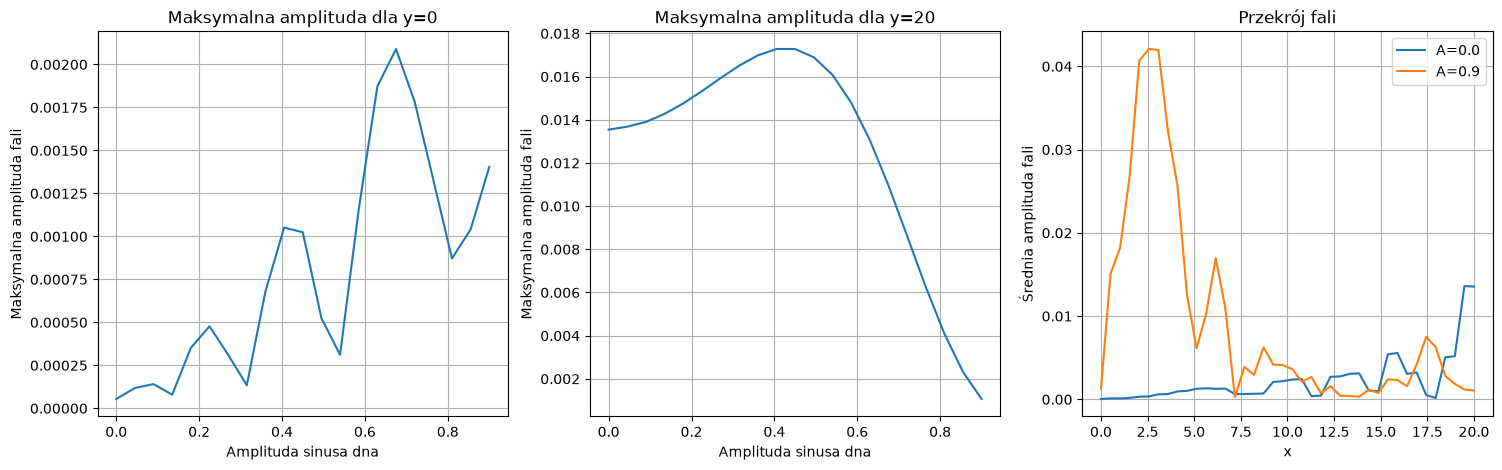

In [69]:
max_amplitude_y_0 = []
max_amplitude_y_n0 = []

for amplitude in sine_amplitudes :
    max_amplitude_y_0.append(np.max(np.abs(np.array(results_amplitudes[amplitude]["output sine"]["h"])[-1,:,0] - np.array(results_amplitudes[amplitude]["bathymetry sine"])[:,0])))
    max_amplitude_y_n0.append(np.max(np.abs(np.array(results_amplitudes[amplitude]["output sine"]["h"])[-1,:,-1] - np.array(results_amplitudes[amplitude]["bathymetry sine"])[:,-1])))


fig, ax = pyplot.subplots(1, 3, figsize=(18, 5))

ax[0].plot(sine_amplitudes, max_amplitude_y_0) 
ax[0].set_title('Maksymalna amplituda dla y=0')
ax[0].set_xlabel("Amplituda sinusa dna")
ax[0].set_ylabel("Maksymalna amplituda fali")

ax[1].plot(sine_amplitudes, max_amplitude_y_n0) 
ax[1].set_title(f'Maksymalna amplituda dla y={n0}')
ax[1].set_xlabel("Amplituda sinusa dna")
ax[1].set_ylabel("Maksymalna amplituda fali")


for amplitude in [sine_amplitudes[0], sine_amplitudes[-1]] :
    mean_amplitude = []
    for i in range(ny) :
        mean_amplitude.append(np.mean(np.abs(np.array(results_amplitudes[amplitude]["output sine"]["h"])[-1,:,i] - np.array(results_amplitudes[amplitude]["bathymetry sine"])[:,i])))

    ax[2].plot(np.linspace(0,n0,nx), mean_amplitude, label=f'A={amplitude}') 
    ax[2].set_title('Przekrój fali')
    ax[2].set_xlabel("x")
    ax[2].set_ylabel("Średnia amplituda fali")
    ax[2].legend()

for a in ax :
    a.grid()

## Analiza wpływu fazy początkowej sinusoidalnego dna

W drugiej części symulacji zbadano wpływ fazy początkowej sinusoidalnego dna na propagację zaburzenia. Amplitudę sinusoidalnego dna ustalono na $A=0.25$, a fazę początkową zmieniano w zakresie od 0 do $2\pi$, wykonując 21 symulacji. Dla każdej wartości fazy początkowej wyznaczono maksymalną amplitudę zaburzenia na krawędziach $y=0$ oraz $y=20$ w ostatnim kroku czasowym. Dodatkowo przeanalizowano profil fali w ostatnim kroku czasowym.

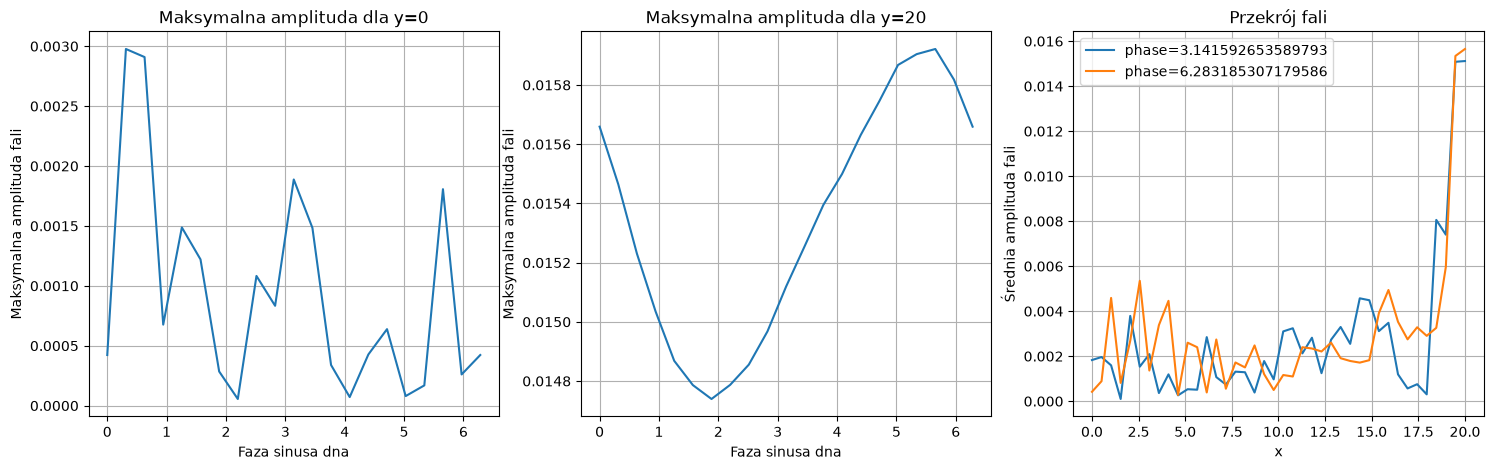

In [70]:
max_amplitude_y_0 = []
max_amplitude_y_n0 = []

for phase in sine_phases :
    max_amplitude_y_0.append(np.max(np.abs(np.array(results_phases[phase]["output sine"]["h"])[-1,:,0] - np.array(results_phases[phase]["bathymetry sine"])[:,0])))
    max_amplitude_y_n0.append(np.max(np.abs(np.array(results_phases[phase]["output sine"]["h"])[-1,:,-1] - np.array(results_phases[phase]["bathymetry sine"])[:,-1])))


fig, ax = pyplot.subplots(1, 3, figsize=(18, 5))

ax[0].plot(sine_phases, max_amplitude_y_0) 
ax[0].set_title('Maksymalna amplituda dla y=0')
ax[0].set_xlabel("Faza sinusa dna")
ax[0].set_ylabel("Maksymalna amplituda fali")

ax[1].plot(sine_phases, max_amplitude_y_n0) 
ax[1].set_title(f'Maksymalna amplituda dla y={n0}')
ax[1].set_xlabel("Faza sinusa dna")
ax[1].set_ylabel("Maksymalna amplituda fali")


for phase in [sine_phases[10], sine_phases[20]] :
    mean_amplitude = []
    for i in range(ny) :
        mean_amplitude.append(np.mean(np.abs(np.array(results_phases[phase]["output sine"]["h"])[-1,:,i] - np.array(results_phases[phase]["bathymetry sine"])[:,i])))

    ax[2].plot(np.linspace(0,n0,nx), mean_amplitude, label=f'phase={phase}') 
    ax[2].set_title('Przekrój fali')
    ax[2].set_xlabel("x")
    ax[2].set_ylabel("Średnia amplituda fali")
    ax[2].legend()

for a in ax :
    a.grid()

In [71]:
dx_vals = [1, 1/2, 1/4, 1/8]
results_dx = {}

for dx in dx_vals :

    nx = int(n0/dx)
    ny = int(n0/dx)

    xi, yi = np.indices((nx,ny))

    X = xi*dx
    Y = yi*dx

    bathymetry_sine = np.ones_like(Y) + 0.25 * np.sin(2*np.pi*2*Y/n0) 
    
    h_initial_sine = bathymetry_sine.copy() 
    h_initial_sine[:,0:int(ny/20)] += A_0

    dt = cfl*dx
    nt = round(T/dt)


    output_sine = ShallowWaterEquationsIntegratorWithBathymetry(
        h_initial=h_initial_sine, bathymetry=bathymetry_sine
    )(
        nt=nt, 
        g=10, 
        dt_over_dxy=(cfl,cfl), 
        outfreq=1
    )

    results_dx[dx] = {"dx": dx,
                  "bathymetry sine": bathymetry_sine,
                  "output sine": output_sine}


In [72]:
dx = 1
dt_vals = [1/4, 1/8, 1/16, 1/32]
results_dt = {}

for dt in dt_vals :

    nx = int(n0/dx)
    ny = int(n0/dx)

    xi, yi = np.indices((nx,ny))

    X = xi*dx
    Y = yi*dx

    bathymetry_sine = np.ones_like(Y) + 0.25 * np.sin(2*np.pi*2*Y/n0) 
    
    h_initial_sine = bathymetry_sine.copy() 
    h_initial_sine[:,0:int(ny/20)] += A_0

    nt = round(T/dt)


    output_sine = ShallowWaterEquationsIntegratorWithBathymetry(
        h_initial=h_initial_sine, bathymetry=bathymetry_sine
    )(
        nt=nt, 
        g=10, 
        dt_over_dxy=(dt/dx,dt/dx), 
        outfreq=1
    )

    results_dt[dt] = {"dt": dt,
                  "bathymetry sine": bathymetry_sine,
                  "output sine": output_sine}

## Zbieżność numeryczna

Przeprowadzono analizę zbieżności względem kroku przestrzennego oraz kroku czasowego. W pierwszej analizie zmieniano krok przestrzenny $dx$, przyjmując wartości: 1, 1/2, 1/4, 1/8. W drugiej analizie krok przestrzenny $dx=1$, zmieniano krok czasowy $dt$: 1/4, 1/8, 1/16, 1/32. Obliczano błąd względny, wyniki porównano z rozwiązaniem uzyskanym dla najdokładniejszej siatki.

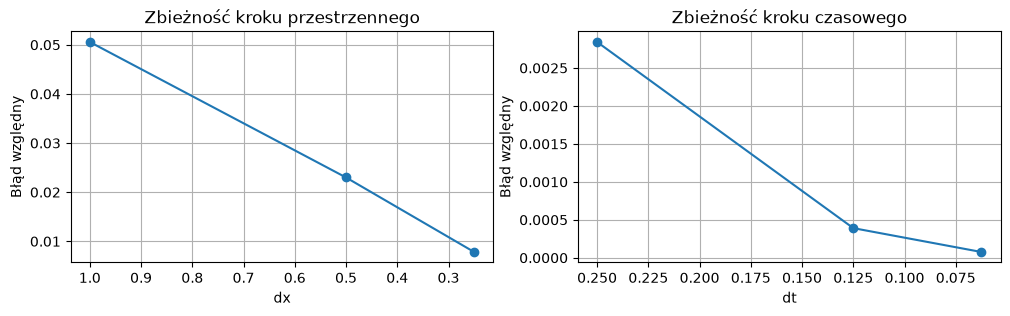

In [73]:
fig, ax = pyplot.subplots(1, 2, figsize=(12, 3))


zbieznosc_dx = []
zbieznosc_dt = []

ref_dx = np.min(dx_vals)
h_ref_dx = results_dx[ref_dx]["output sine"]['h'][-1]

ref_dt = np.min(dt_vals)
h_ref_dt = results_dt[ref_dt]["output sine"]['h'][-1]


for dx in dx_vals[:-1] :
    h = results_dx[dx]["output sine"]['h'][-1]

    h_interp = zoom(h, dx/ref_dx, order=1)

    blad = np.linalg.norm(h_interp - h_ref_dx) / np.linalg.norm(h_ref_dx)

    zbieznosc_dx.append(blad)

for dt in dt_vals[:-1] :
    h = results_dt[dt]["output sine"]['h'][-1]

    blad = np.linalg.norm(h - h_ref_dt) / np.linalg.norm(h_ref_dt)

    zbieznosc_dt.append(blad)

ax[0].plot(dx_vals[:-1], zbieznosc_dx, 'o-')
ax[0].set_xlabel('dx')
ax[0].set_ylabel('Błąd względny')
ax[0].set_title('Zbieżność kroku przestrzennego')

ax[1].plot(dt_vals[:-1], zbieznosc_dt, 'o-')
ax[1].set_xlabel('dt')
ax[1].set_ylabel('Błąd względny')
ax[1].set_title('Zbieżność kroku czasowego')


for a in ax :
    a.grid()
    a.invert_xaxis()
